# 03 · Customer load profiling with k-means clustering
**Level 2 · Descriptive analytics (unsupervised)** &nbsp;|&nbsp; Course link: *Module 4 – identification of customer types
using k-means clustering*

A distribution grid operator knows *how much* each customer consumes per year, but not *when*. Customers with the same
annual energy can stress the grid very differently: an evening-peaking household adds to the system peak, an office
that consumes during the day does not. Grouping customers by the **shape** of their load curve (without labels) is a
classic unsupervised task.

**Data:** real hourly consumption of 354 customers in Portugal for 2014 (UCI *ElectricityLoadDiagrams*).

## The k-means algorithm
Given profile vectors $x_1,\dots,x_n$ and a number of clusters $k$, k-means minimises the within-cluster sum of squares
$$J = \sum_{i=1}^{n}\min_{j}\,\lVert x_i-\mu_j\rVert^2,\qquad d(p,q)=\sqrt{\textstyle\sum_{h}(p_h-q_h)^2}$$
by alternating two steps until nothing changes: **assign** every profile to its nearest centroid, then **move** every
centroid to the mean of its profiles. The result depends on the random start, so it is run several times
(`n_init`) with *k-means++* initialisation.

(8760, 354)


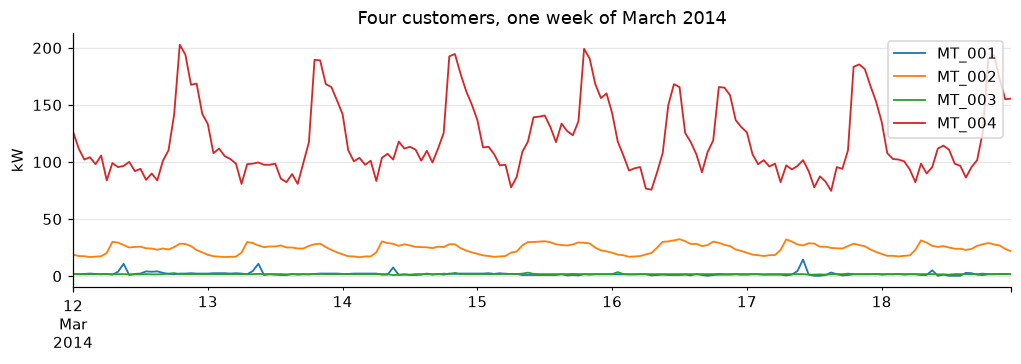

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from energy_ai import uci_customers, style
style()

df = uci_customers(2014, "1h")           # 8760 hours × 354 customers [kW]
print(df.shape)
fig, ax = plt.subplots(figsize=(11, 3))
df.iloc[24 * 7 * 10: 24 * 7 * 11, :4].plot(ax=ax, lw=1.2); ax.set(title="Four customers, one week of March 2014", ylabel="kW"); plt.show()

## 1. Features: the normalised average day
For each customer we build its **typical weekday** and **typical weekend day** (24 + 24 hourly means) and divide by
the customer's mean consumption. Normalising removes the size, so clusters capture *behaviour*, not volume.

In [2]:
weekday = df[df.index.dayofweek < 5].groupby(df[df.index.dayofweek < 5].index.hour).mean()
weekend = df[df.index.dayofweek >= 5].groupby(df[df.index.dayofweek >= 5].index.hour).mean()
profiles = pd.concat([weekday, weekend]).T                       # customers × 48
profiles.columns = [f"wd_{h}" for h in range(24)] + [f"we_{h}" for h in range(24)]
Xp = profiles.div(profiles.mean(axis=1), axis=0)                  # shape only (mean = 1)
Xp = Xp[np.isfinite(Xp).all(axis=1)]

# k-means is sensitive to outliers: one extremely "peaky" customer would grab a whole cluster for itself.
# We set aside customers whose typical day peaks above 4x their mean and look at them separately.
outliers = Xp.index[Xp.max(axis=1) > 4]
Xp = Xp.drop(outliers)
print("feature matrix:", Xp.shape, "| set aside as outliers:", list(outliers))

feature matrix: (353, 48) | set aside as outliers: ['MT_093']


## 2. How many clusters? Elbow and silhouette
* **Elbow:** $J$ always decreases with $k$; we look for the point where adding clusters stops paying off.
* **Silhouette:** for each point $s=(b-a)/\max(a,b)$, with $a$ = mean distance to its own cluster and $b$ = to the
  nearest other cluster; the average is in $[-1, 1]$, higher is better.

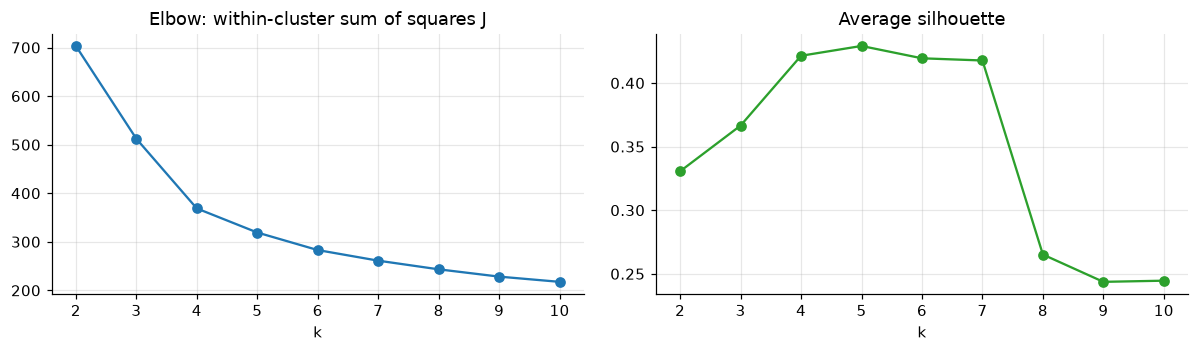

{2: 0.331, 3: 0.367, 4: 0.421, 5: 0.429, 6: 0.419, 7: 0.418, 8: 0.265, 9: 0.244, 10: 0.245}


In [3]:
ks = range(2, 11)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=0).fit(Xp)
    inertia.append(km.inertia_); sil.append(silhouette_score(Xp, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(list(ks), inertia, "o-"); ax[0].set(title="Elbow: within-cluster sum of squares J", xlabel="k")
ax[1].plot(list(ks), sil, "o-", color="tab:green"); ax[1].set(title="Average silhouette", xlabel="k")
plt.tight_layout(); plt.show()
print({k: round(s, 3) for k, s in zip(ks, sil)})

The silhouette is best for $k$ around 4–6 and drops sharply after 8; the elbow bends in the same region. We choose
$k=5$: close to the best silhouette, and each group is still easy to interpret for a grid operator.

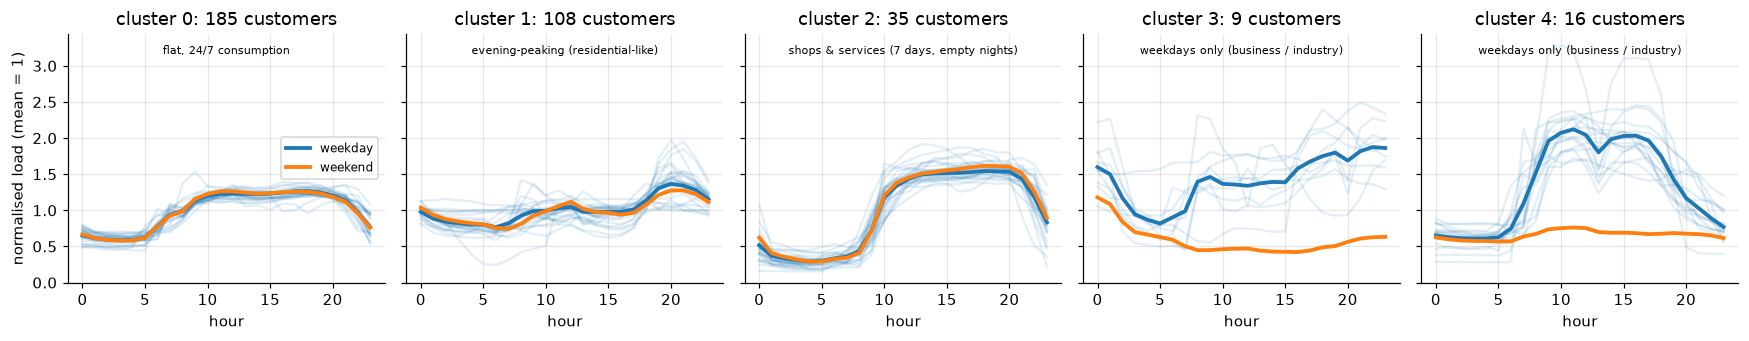

,customers,type,weekday peak hour,peak-to-average ratio,weekend / weekday energy
cluster,,,,,
0,185,"flat, 24/7 consumption",18,1.27,1.00
1,108,evening-peaking (residential-like),20,1.35,0.98
2,35,"shops & services (7 days, empty nights)",18,1.57,1.03
3,9,weekdays only (business / industry),22,1.33,0.42
4,16,weekdays only (business / industry),11,1.58,0.49


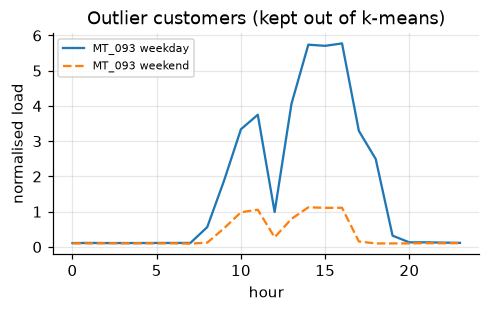

In [4]:
K = 5
km = KMeans(n_clusters=K, n_init=50, random_state=0).fit(Xp)
labels = pd.Series(km.labels_, index=Xp.index)
cent = pd.DataFrame(km.cluster_centers_, columns=Xp.columns)

def describe(c):
    """Name an archetype from measurable features of its centroid."""
    wd, we = np.asarray(c[:24]), np.asarray(c[24:])
    peak = int(np.argmax(wd))
    weekend_ratio = we.mean() / wd.mean()
    night_day = wd[0:6].mean() / wd[10:20].mean()
    evening = wd[18:22].mean() / wd[10:16].mean()
    if weekend_ratio < 0.7:
        kind = "weekdays only (business / industry)"
    elif evening > 1.15:
        kind = "evening-peaking (residential-like)"
    elif night_day < 0.45:
        kind = "shops & services (7 days, empty nights)"
    elif wd.max() / wd.mean() < 1.4:
        kind = "flat, 24/7 consumption"
    else:
        kind = "daytime, 7 days"
    return kind, peak

fig, axes = plt.subplots(1, K, figsize=(16, 3.2), sharey=True)
summary = []
for j, ax in enumerate(axes):
    members = Xp[labels == j]
    for _, row in members.sample(min(25, len(members)), random_state=0).iterrows():
        ax.plot(range(24), row.values[:24], color="tab:blue", alpha=0.12)
    ax.plot(range(24), cent.iloc[j, :24], color="tab:blue", lw=2.5, label="weekday")
    ax.plot(range(24), cent.iloc[j, 24:], color="tab:orange", lw=2.5, label="weekend")
    kind, peak = describe(cent.iloc[j].values)
    ax.set(title=f"cluster {j}: {len(members)} customers", xlabel="hour"); ax.text(0.5, 0.92, kind, transform=ax.transAxes, ha="center", fontsize=7.5)
    wd = cent.iloc[j, :24].values
    summary.append({"cluster": j, "customers": len(members), "type": kind, "weekday peak hour": peak,
                    "peak-to-average ratio": wd.max() / wd.mean(), "weekend / weekday energy": cent.iloc[j, 24:].mean() / wd.mean()})
axes[0].set_ylabel("normalised load (mean = 1)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
display(pd.DataFrame(summary).set_index("cluster").round(2))
if len(outliers):
    fig, ax = plt.subplots(figsize=(5, 2.6))
    out_prof = profiles.loc[outliers].div(profiles.loc[outliers].mean(axis=1), axis=0)
    for name, row in out_prof.iterrows():
        ax.plot(range(24), row.values[:24], label=f"{name} weekday"); ax.plot(range(24), row.values[24:], ls="--", label=f"{name} weekend")
    ax.set(title="Outlier customers (kept out of k-means)", xlabel="hour", ylabel="normalised load"); ax.legend(fontsize=7); plt.show()

The outliers set aside earlier have their own, extreme shape (for example a site that runs only a few hours a day):

Each centroid is an **archetype**: a typical behaviour. The peak-to-average ratio (PAR) tells the operator how
"peaky" a group is: high-PAR groups drive transformer peaks, so they are the target for flexibility programmes and
time-of-use tariffs.

## 3. Seeing the clusters: a 2-D projection
48 dimensions cannot be plotted; PCA (notebook-free preview of dimensionality reduction) projects them onto the two
directions of largest variance.

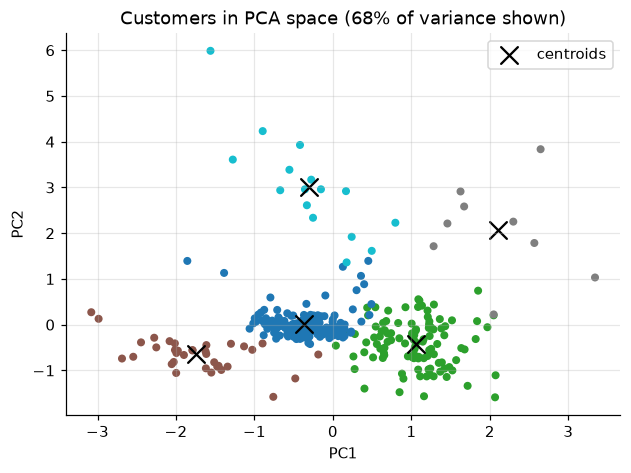

In [5]:
pc = PCA(n_components=2).fit(Xp)
P2 = pc.transform(Xp)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
sc = ax.scatter(P2[:, 0], P2[:, 1], c=labels, cmap="tab10", s=18)
ax.scatter(*pc.transform(cent.values).T, c="k", marker="x", s=120, label="centroids")
ax.set(title=f"Customers in PCA space ({pc.explained_variance_ratio_.sum():.0%} of variance shown)", xlabel="PC1", ylabel="PC2")
ax.legend(); plt.show()

## 4. Why it matters for the grid: contribution to the system peak
The **coincidence factor** of a group compares its load at the *system* peak hour to its own peak. Groups that peak
together with the system are the expensive ones.

In [6]:
total = df.sum(axis=1)
peak_hour = total.idxmax()
rows = []
for j in range(K):
    cols = labels.index[labels == j]
    grp = df[cols].sum(axis=1)
    rows.append({"cluster": j, "type": summary[j]["type"], "share of annual energy": grp.sum() / total.sum(),
                 "share of system peak": grp.loc[peak_hour] / total.loc[peak_hour],
                 "coincidence factor": grp.loc[peak_hour] / grp.max()})
print("system peak hour:", peak_hour)
display(pd.DataFrame(rows).set_index("cluster").style.format({"share of annual energy": "{:.1%}", "share of system peak": "{:.1%}",
                                                             "coincidence factor": "{:.2f}"}))

system peak hour: 2014-08-26 17:00:00


,type,share of annual energy,share of system peak,coincidence factor
cluster,,,,
0,"flat, 24/7 consumption",47.5%,38.0%,0.94
1,evening-peaking (residential-like),18.7%,11.0%,0.73
2,"shops & services (7 days, empty nights)",32.7%,50.3%,1.00
3,weekdays only (business / industry),0.4%,0.2%,0.55
4,weekdays only (business / industry),0.7%,0.4%,0.59


**Reading the table:** a group's share of the *system peak* can be very different from its share of *energy*. The
group that peaks exactly when the system peaks (coincidence factor ≈ 1) causes a disproportionate part of the peak,
and the peak is what sizes cables and transformers. This is where a DSO targets flexibility and peak tariffs, while
groups with a low coincidence factor can grow without new grid investment.

## Key takeaways
* k-means groups customers by load **shape** once the size is normalised away; the centroids are interpretable archetypes.
* Choose $k$ with the elbow and silhouette **and** with domain sense (a useful number of tariff / programme groups).
* k-means is stochastic: use many restarts (`n_init`) and a fixed `random_state` for reproducibility.
* Euclidean distance compares hours one by one; if two customers have the same shape shifted by an hour, Dynamic Time
  Warping (DTW) would see them as similar while k-means would not.

**Try it yourself:** cluster *days* instead of customers (each day of the total load = one 24-h vector) to find
"typical days" for planning studies; or use `KMeans(n_clusters=8)` and see which archetypes split.